**Импорт данных**

In [ ]:
%pip install git+https://github.com/Eickland/HumSpectra.git --upgrade

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from pathlib import Path
import HumSpectra.fluorescence as fl
import HumSpectra.ultraviolet as uv
import HumSpectra.utilits as ut
import HumSpectra.math_stat as st
from sklearn.decomposition import PCA
from scipy import stats

In [18]:
sns.set_style("dark")
%matplotlib inline

wdir_save = Path.cwd().parent/ "Server" / "Received data" / "Compare data"

In [19]:
def add_median_labels(ax, fmt='.3f'):

    lines = ax.get_lines()
    boxes = [c for c in ax.get_children() if type(c).__name__ == 'PathPatch']
    lines_per_box = int(len(lines) / len(boxes))

    for median in lines[4:len(lines):lines_per_box]:

        x, y = (data.mean() for data in median.get_data())

        # choose value depending on horizontal or vertical plot orientation

        value = x if (median.get_xdata()[1] - median.get_xdata()[0]) == 0 else y
        text = ax.text(x, y, f'{value:{fmt}}', ha='center', va='center',
                       fontweight='bold', color='white')
        
        # create median-colored border around white text for contrast
        text.set_path_effects([
            path_effects.Stroke(linewidth=3, foreground=median.get_color()),
            path_effects.Normal(),
        ])

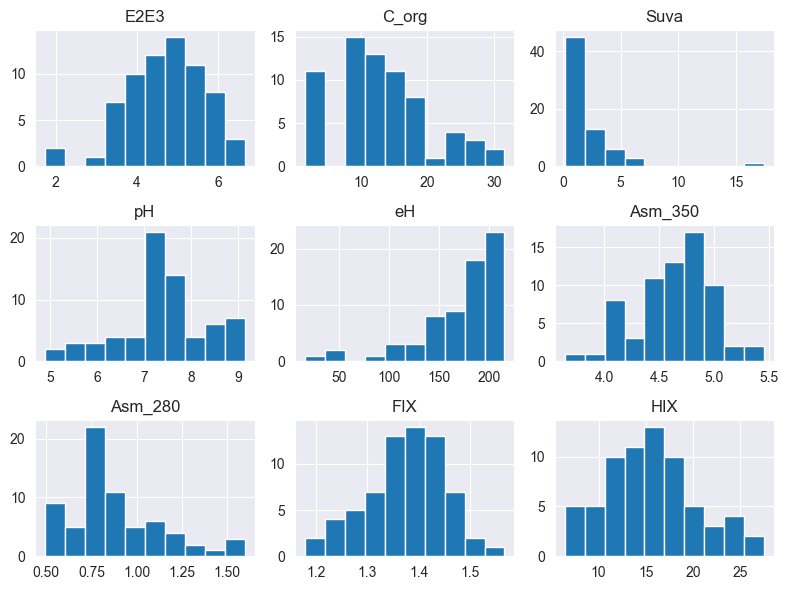

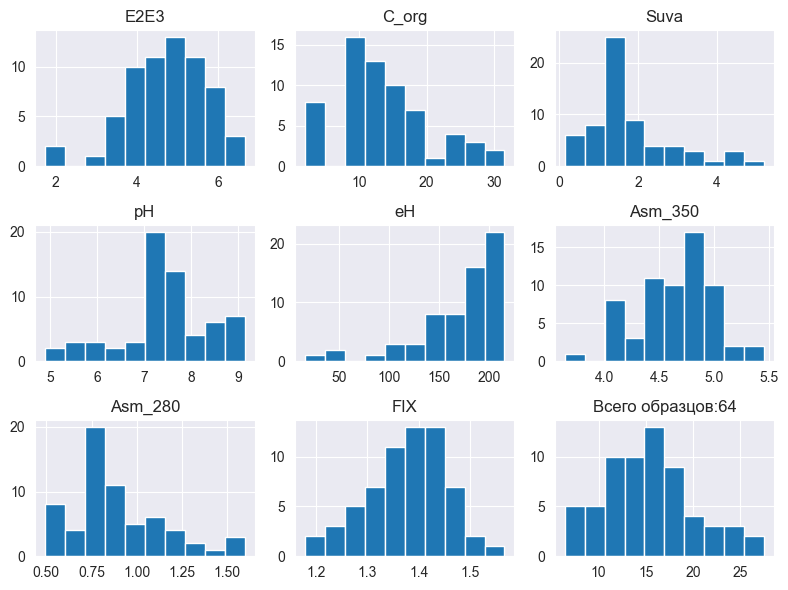

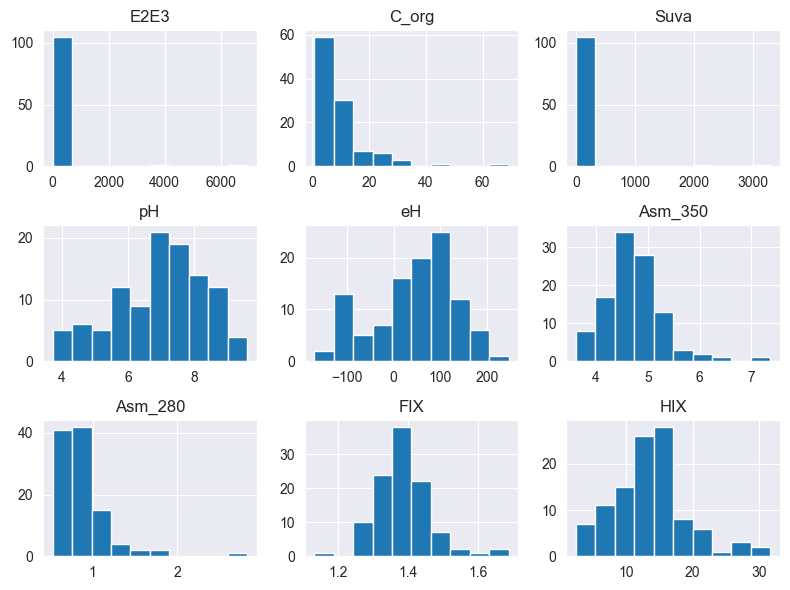

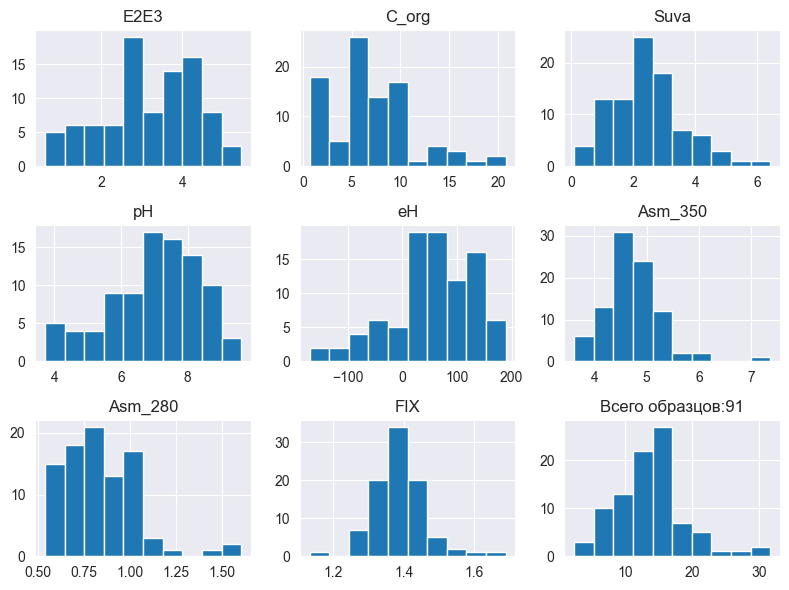

In [23]:
date_list = ["2024","2025"]
fluo_settings_list = [0,1]
iqr_setings_list = [2,2.5]
data_list = []

for i,date in enumerate(date_list):
    wdir_date = Path.cwd().parent / "Initial data" / date

    fluo_path = Path.joinpath(wdir_date, "Fluorescence")
    uv_path = Path.joinpath(wdir_date, "UV","Individual spectra")

    carbon_data = pd.read_excel(Path.joinpath(wdir_date, 'C_org.xlsx'))
    geodata = pd.read_excel(Path.joinpath(wdir_date, 'GeoData.xlsx'))

    fluo_spectra = ut.load_spectra_data(fluo_path, fl.read_fluo_3d, index_col=fluo_settings_list[i])
    uv_spectra = ut.load_spectra_data(uv_path, uv.read_csv_uv, spectra_type="absorption")

    fl_data = ut.spectra_to_df(fluo_spectra, {
        "Asm_350": fl.asm_350, "Asm_280": fl.asm_280,
        "FIX": fl.fluo_index, "HIX": fl.humin_index
    })

    uv_data = ut.spectra_to_df(uv_spectra, {
        "E2E3": uv.e2_e3, "epsilon": uv.epsilon
    })

    MainData_init = (uv_data.merge(carbon_data, on="Sample")
                    .assign(Suva=lambda x: 100*x.epsilon / x.C_org)
                    .drop(columns=["epsilon"])
                    .merge(geodata[["Sample", "pH", "eH"]], on="Sample")
                    .merge(fl_data, on=["Sample", "Class", "Subclass"]))

    numeric_cols = MainData_init.select_dtypes(include=['float']).columns
    MainData_init[numeric_cols] = MainData_init[numeric_cols].map(lambda x: float(f"{x:.4g}"))
    MainData_init.set_index(["Class","Subclass","Sample"],inplace=True)

    storage_list = MainData_init.index.get_level_values(1).unique().to_list()
    common_storage_list = ["Storage 2","Storage 3","Storage 4","Storage 5","Storage 6","Storage 7"]
    feature_columns = ["E2E3","C_org","Suva","Asm_350","pH","Asm_280"]
    feature_group_one = ["E2E3","C_org","Suva"]
    feature_group_second = ["Asm_350","pH","Asm_280"]

    
    MainData_init.hist(figsize=(8,6))
    plt.tight_layout()
    plt.savefig(Path.joinpath(wdir_save,"Graphs",f"init_hist_{date}.png"))
    plt.show()

    MainData = st.delete_eject_iqr(MainData_init,iqr_param=iqr_setings_list[i],multi_index=False,columns=["Suva","Asm_280","C_org"])

    MainData.hist(figsize=(8,6))
    plt.title(f"Всего образцов:{len(MainData)}")
    plt.tight_layout()
    plt.savefig(Path.joinpath(wdir_save,"Graphs",f"hist_{date}.png"))
    plt.show()

    MainData_init.to_excel(Path.joinpath(wdir_save,"Documents","MainData_init.xlsx"))
    MainData.to_excel(Path.joinpath(wdir_save,"Documents","MainData.xlsx"))
    MainData_init.describe().to_excel(Path.joinpath(wdir_save,"Documents","MainData_init_statistic.xlsx"))
    MainData.describe().to_excel(Path.joinpath(wdir_save,"Documents","MainData_statistic.xlsx"))

    MainData_init.to_html(Path.joinpath(wdir_save,"Templates","MainData_init.html"))
    MainData.to_html(Path.joinpath(wdir_save,"Templates","MainData.html"))
    MainData_init.describe().to_html(Path.joinpath(wdir_save,"Templates","MainData_init_statistic.html"))
    MainData.describe().to_html(Path.joinpath(wdir_save,"Templates","MainData_statistic.html"))

    data_list.append(MainData)

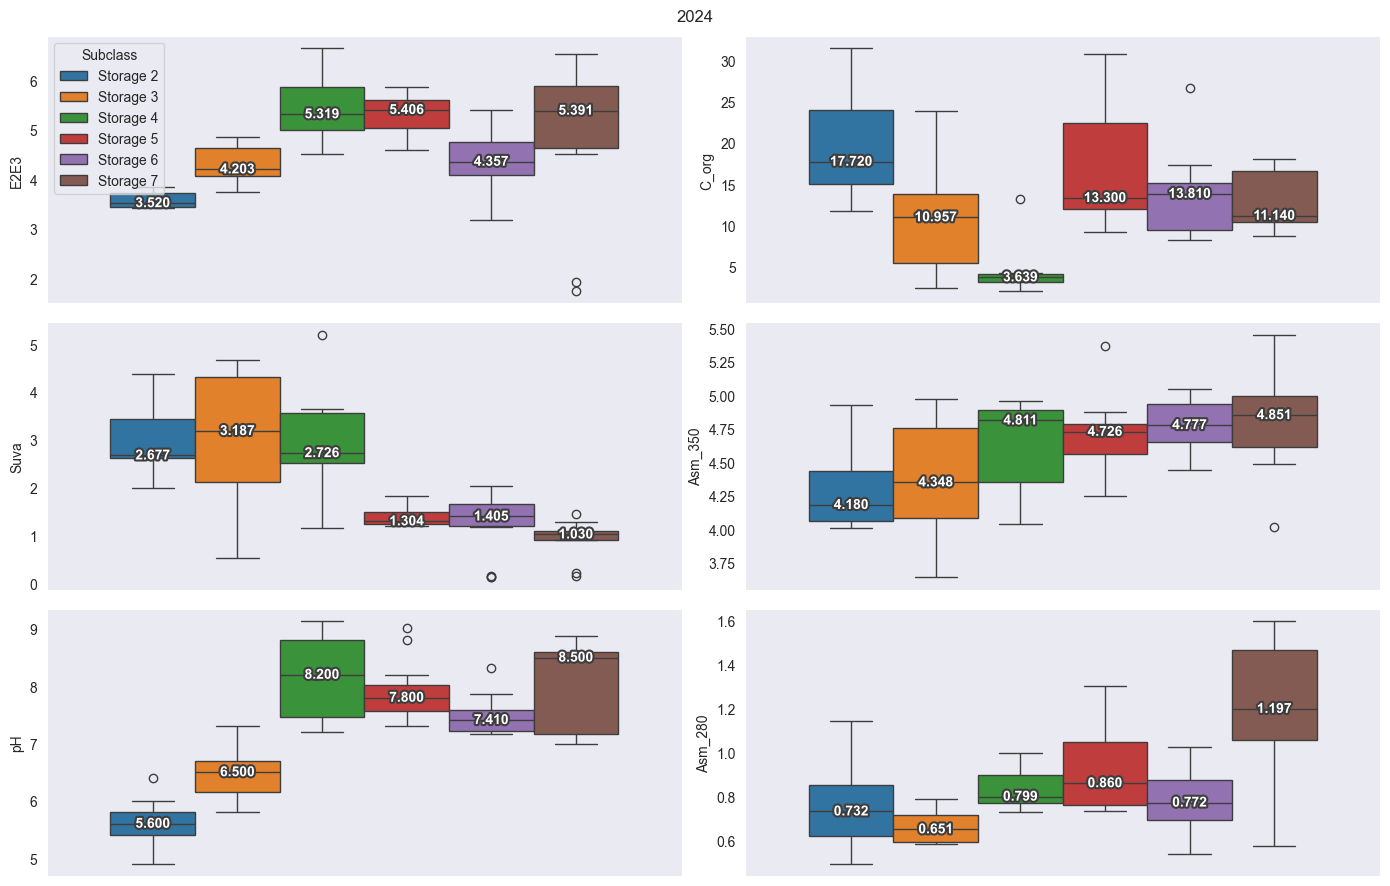

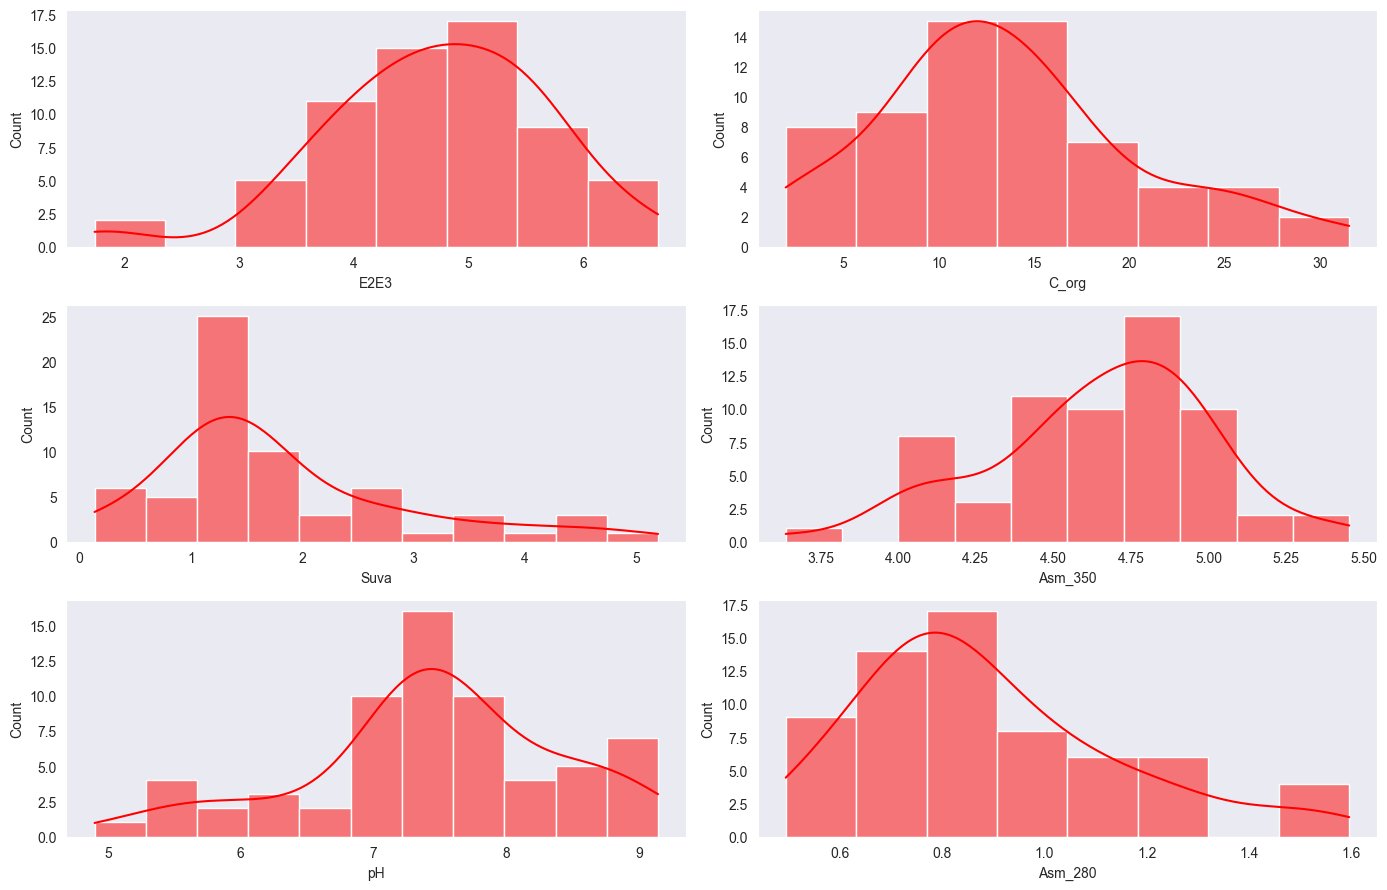

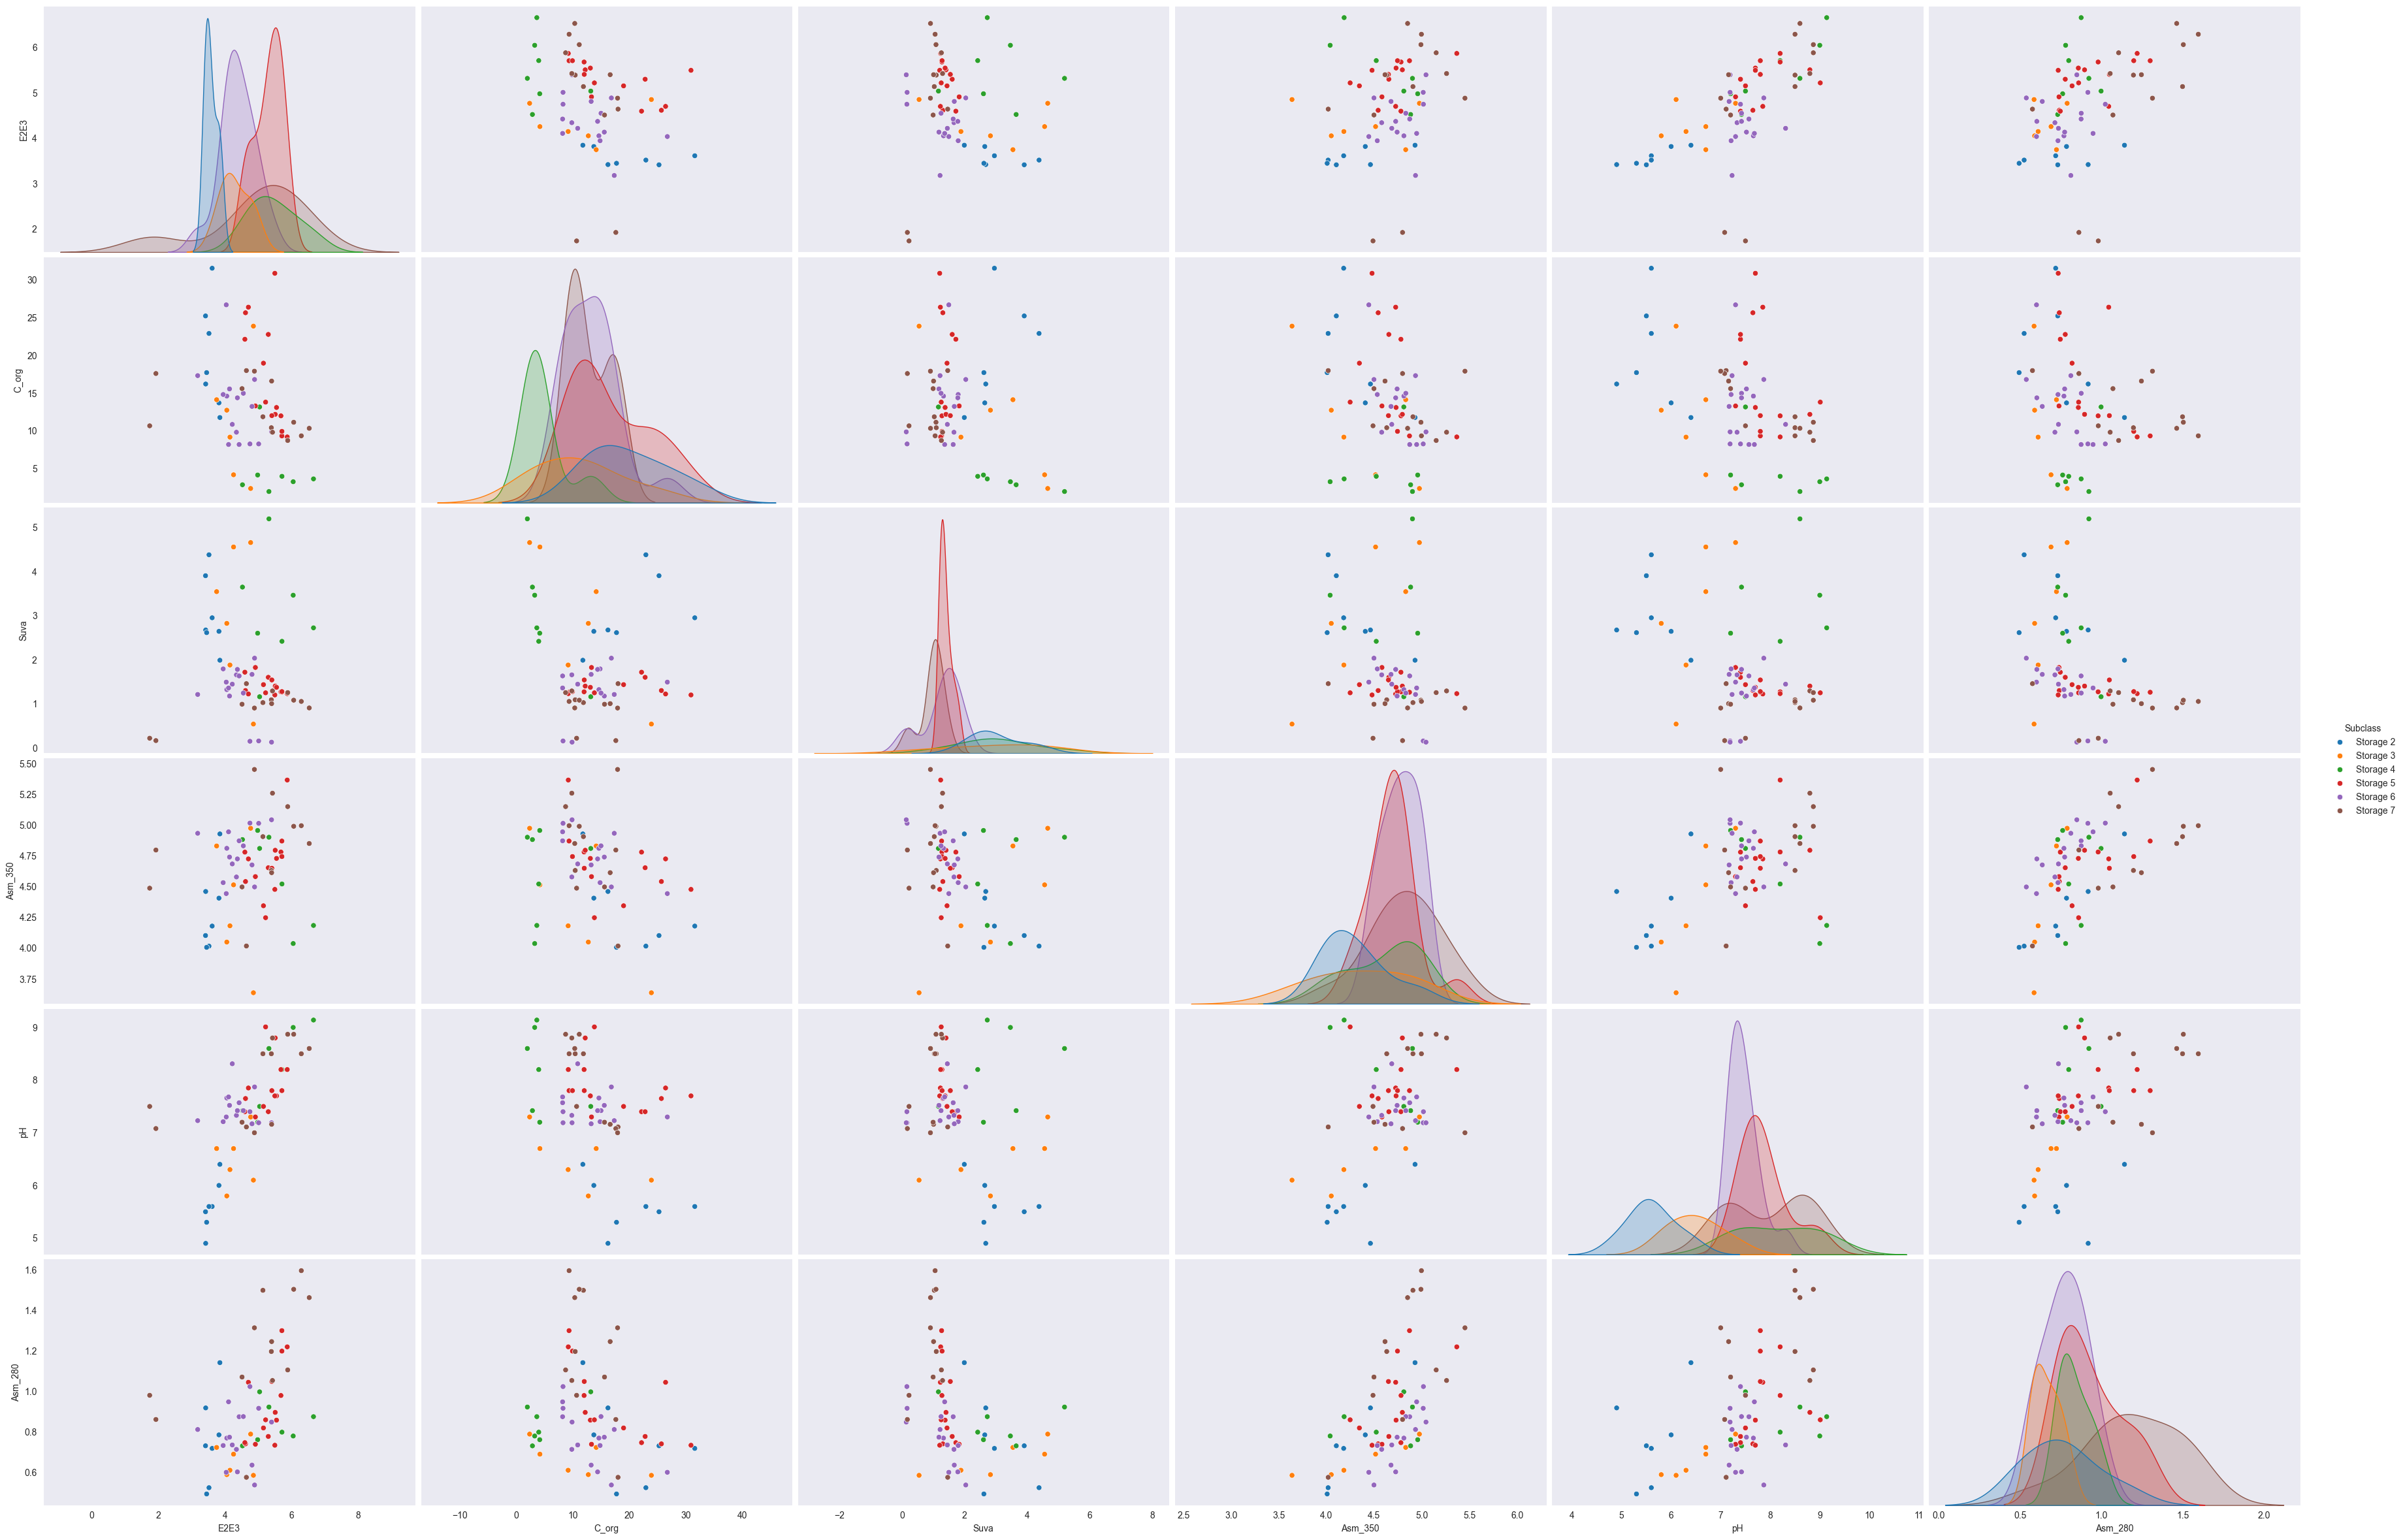

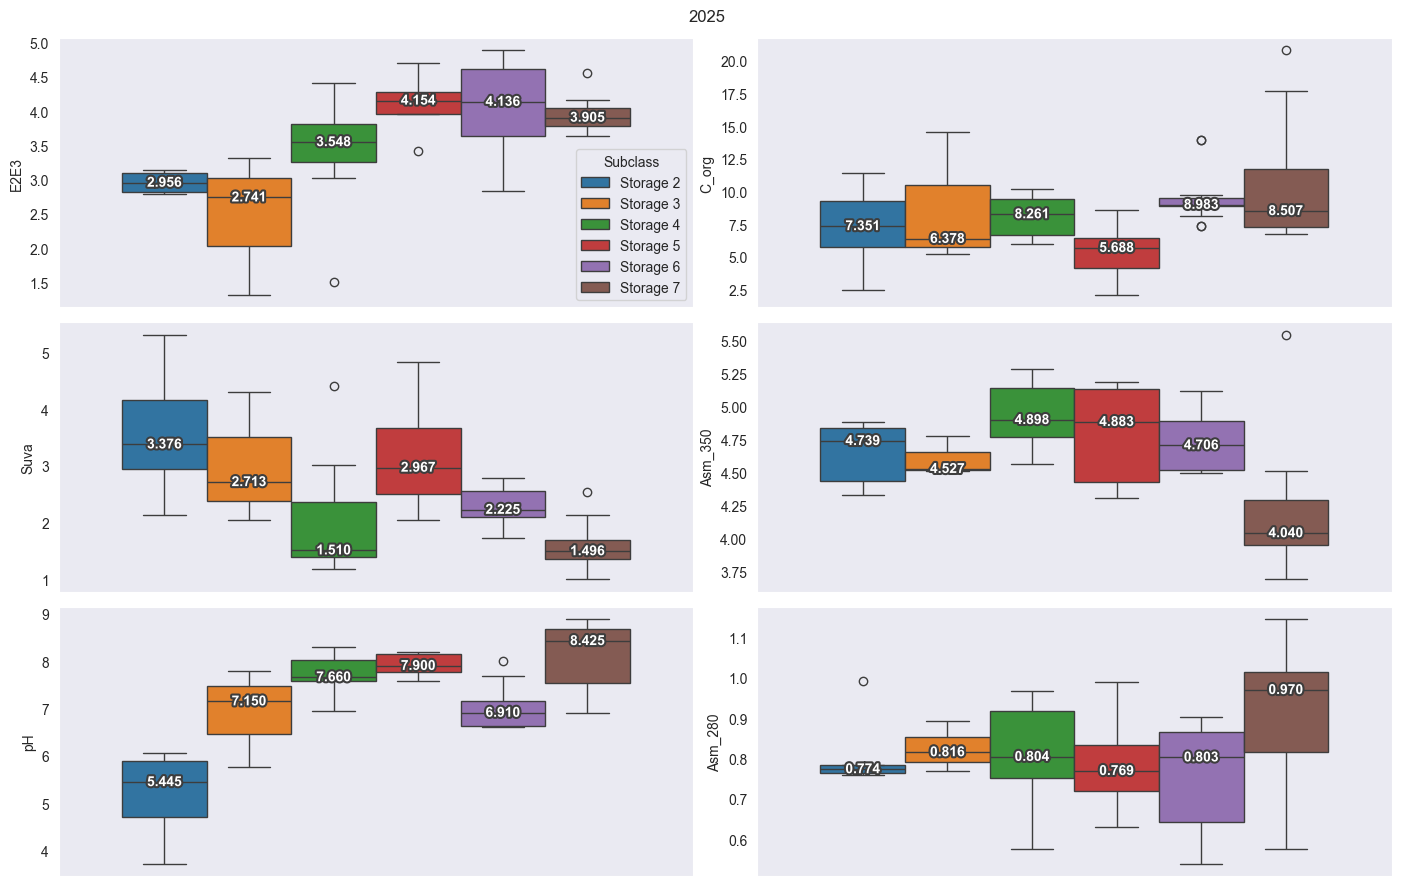

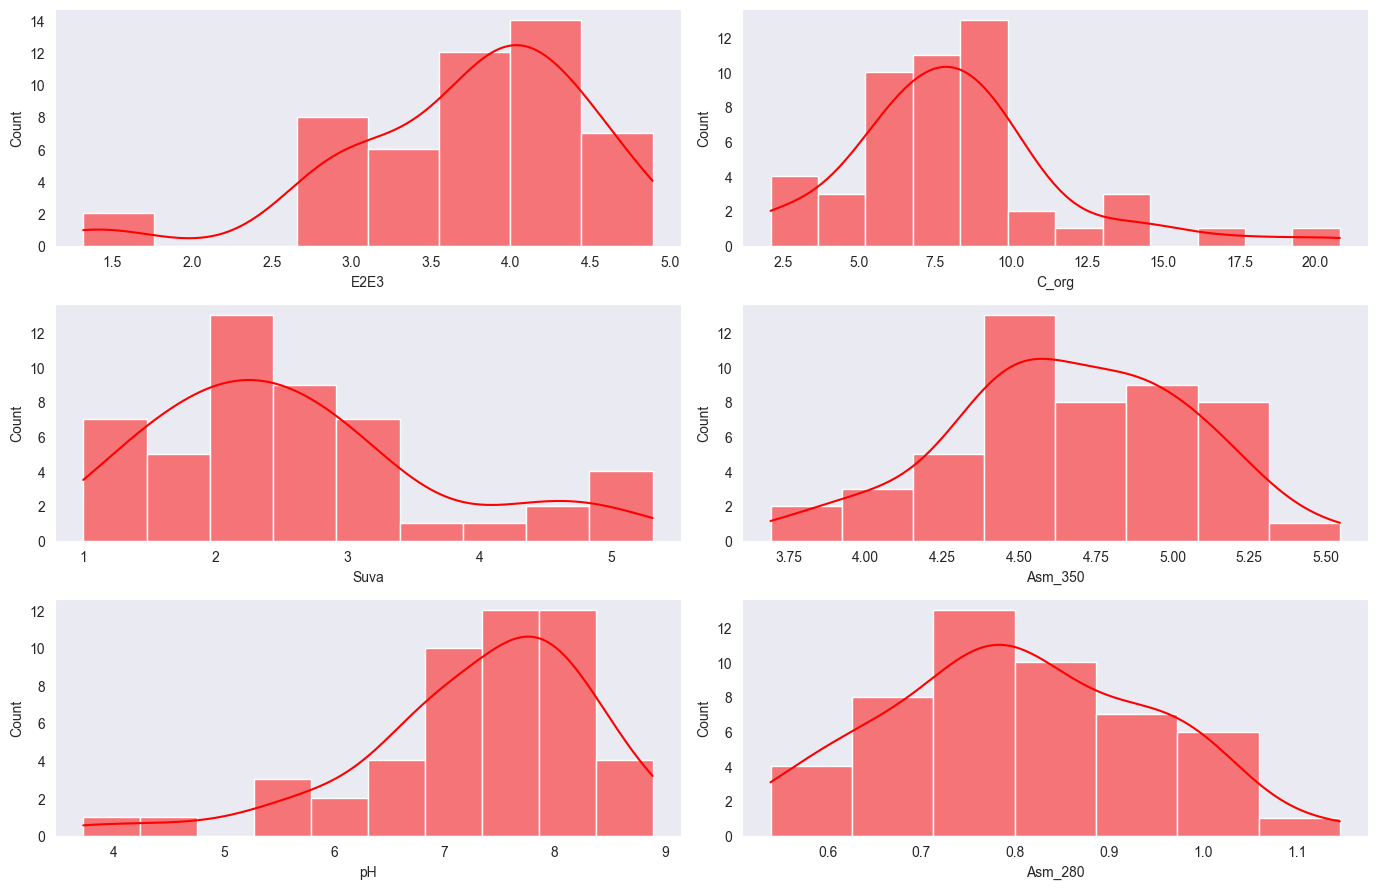

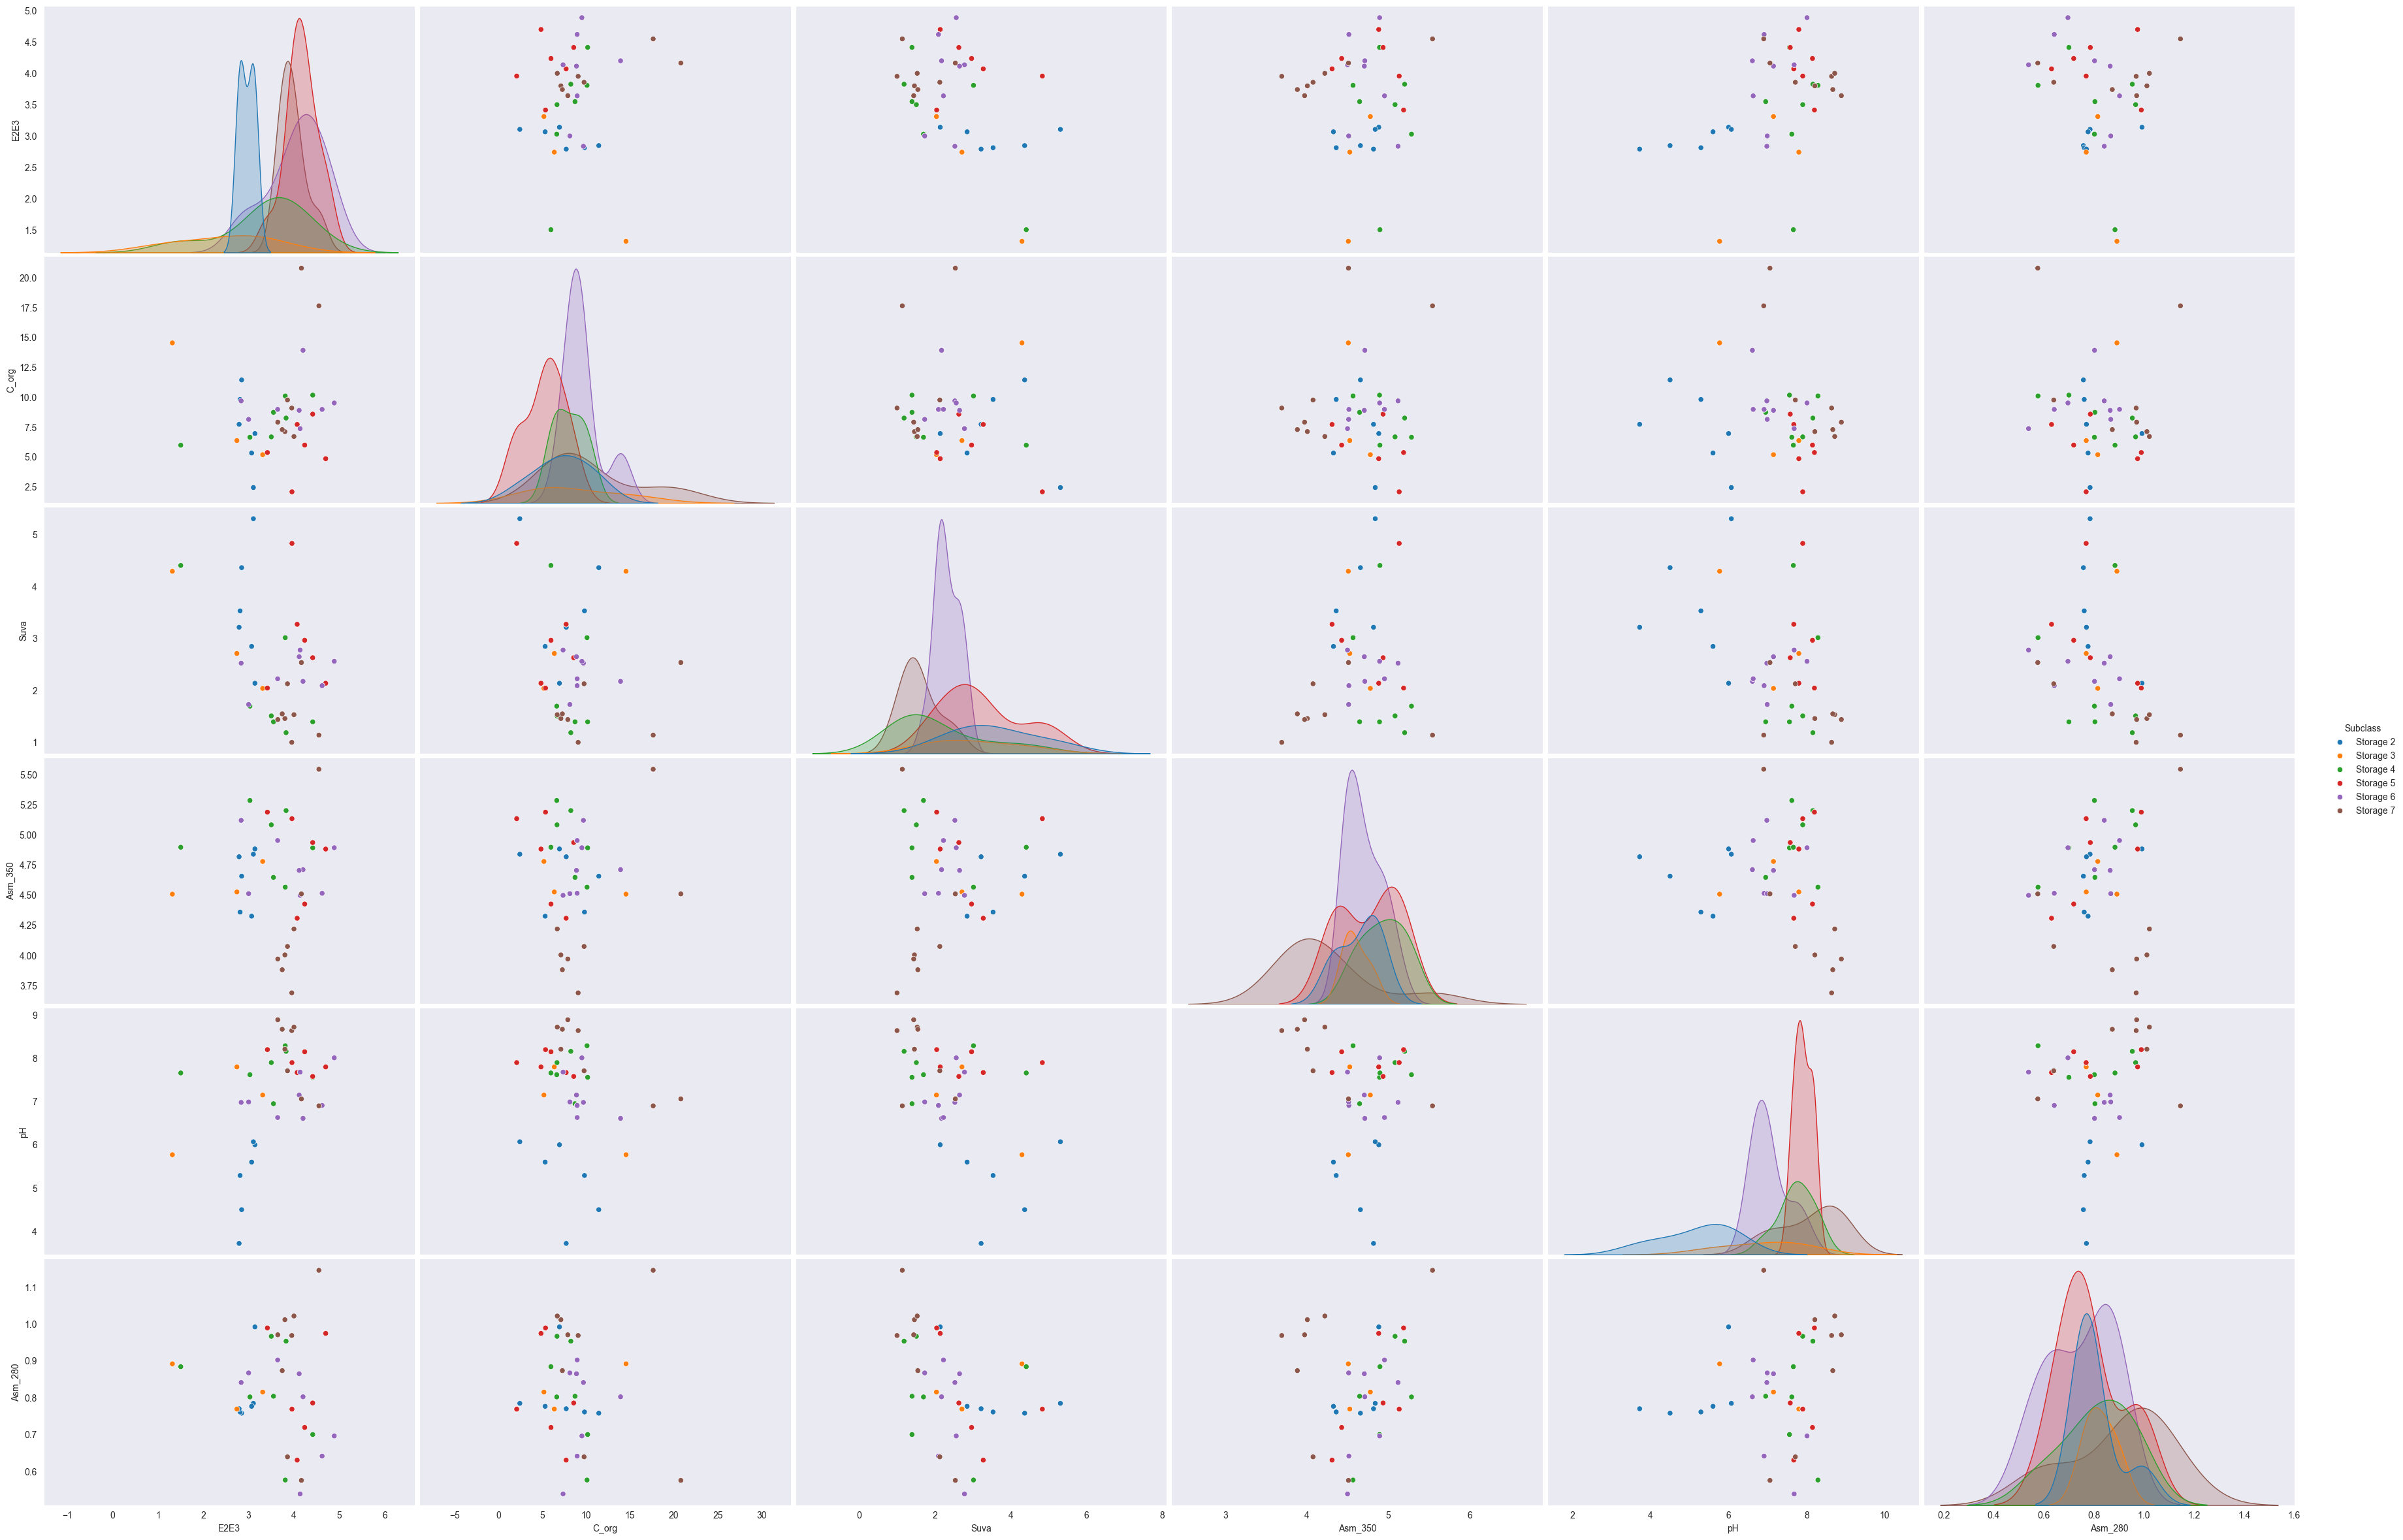

In [24]:
for i,data in enumerate(data_list):

    fig,axes = plt.subplots(3,2,figsize=(14,9))
    axes_flat = axes.flat

    plt.suptitle(f"{date_list[i]}")

    for k,feature in enumerate(feature_columns):

        feature_data = data[feature].loc["ADOM",common_storage_list]

        if k == 0:
            box = sns.boxplot(data=feature_data.reset_index(),y=feature,hue="Subclass",ax=axes_flat[k])
        else:
            box = sns.boxplot(data=feature_data.reset_index(),y=feature,hue="Subclass",ax=axes_flat[k],legend=False)

        add_median_labels(box)

    plt.tight_layout()
    plt.savefig(Path.joinpath(wdir_save,"Graphs",f"boxplot_{date_list[i]}.png"))
    plt.show()

    fig,axes = plt.subplots(3,2,figsize=(14,9))
    axes_flat = axes.flat

    for k,feature in enumerate(feature_columns):

        feature_data = data[feature].loc["ADOM",common_storage_list]

        if k == 0:

            sns.histplot(feature_data, label=date_list[i], kde=True, color='red', alpha=0.5,ax=axes_flat[k])

        else:

            sns.histplot(feature_data, label=date_list[i], kde=True, color='red', alpha=0.5,ax=axes_flat[k])
        
    plt.tight_layout()
    plt.savefig(Path.joinpath(wdir_save,"Graphs",f"kde_{date_list[i]}.png"))
    plt.show()

    sns.pairplot(data.loc[pd.IndexSlice["ADOM", common_storage_list],:].reset_index(),hue="Subclass",vars=feature_columns,height=4,aspect=1.5)
    plt.savefig(Path.joinpath(wdir_save,"Graphs",f"pairplot_{date_list[i]}.png"))
    plt.show()
    

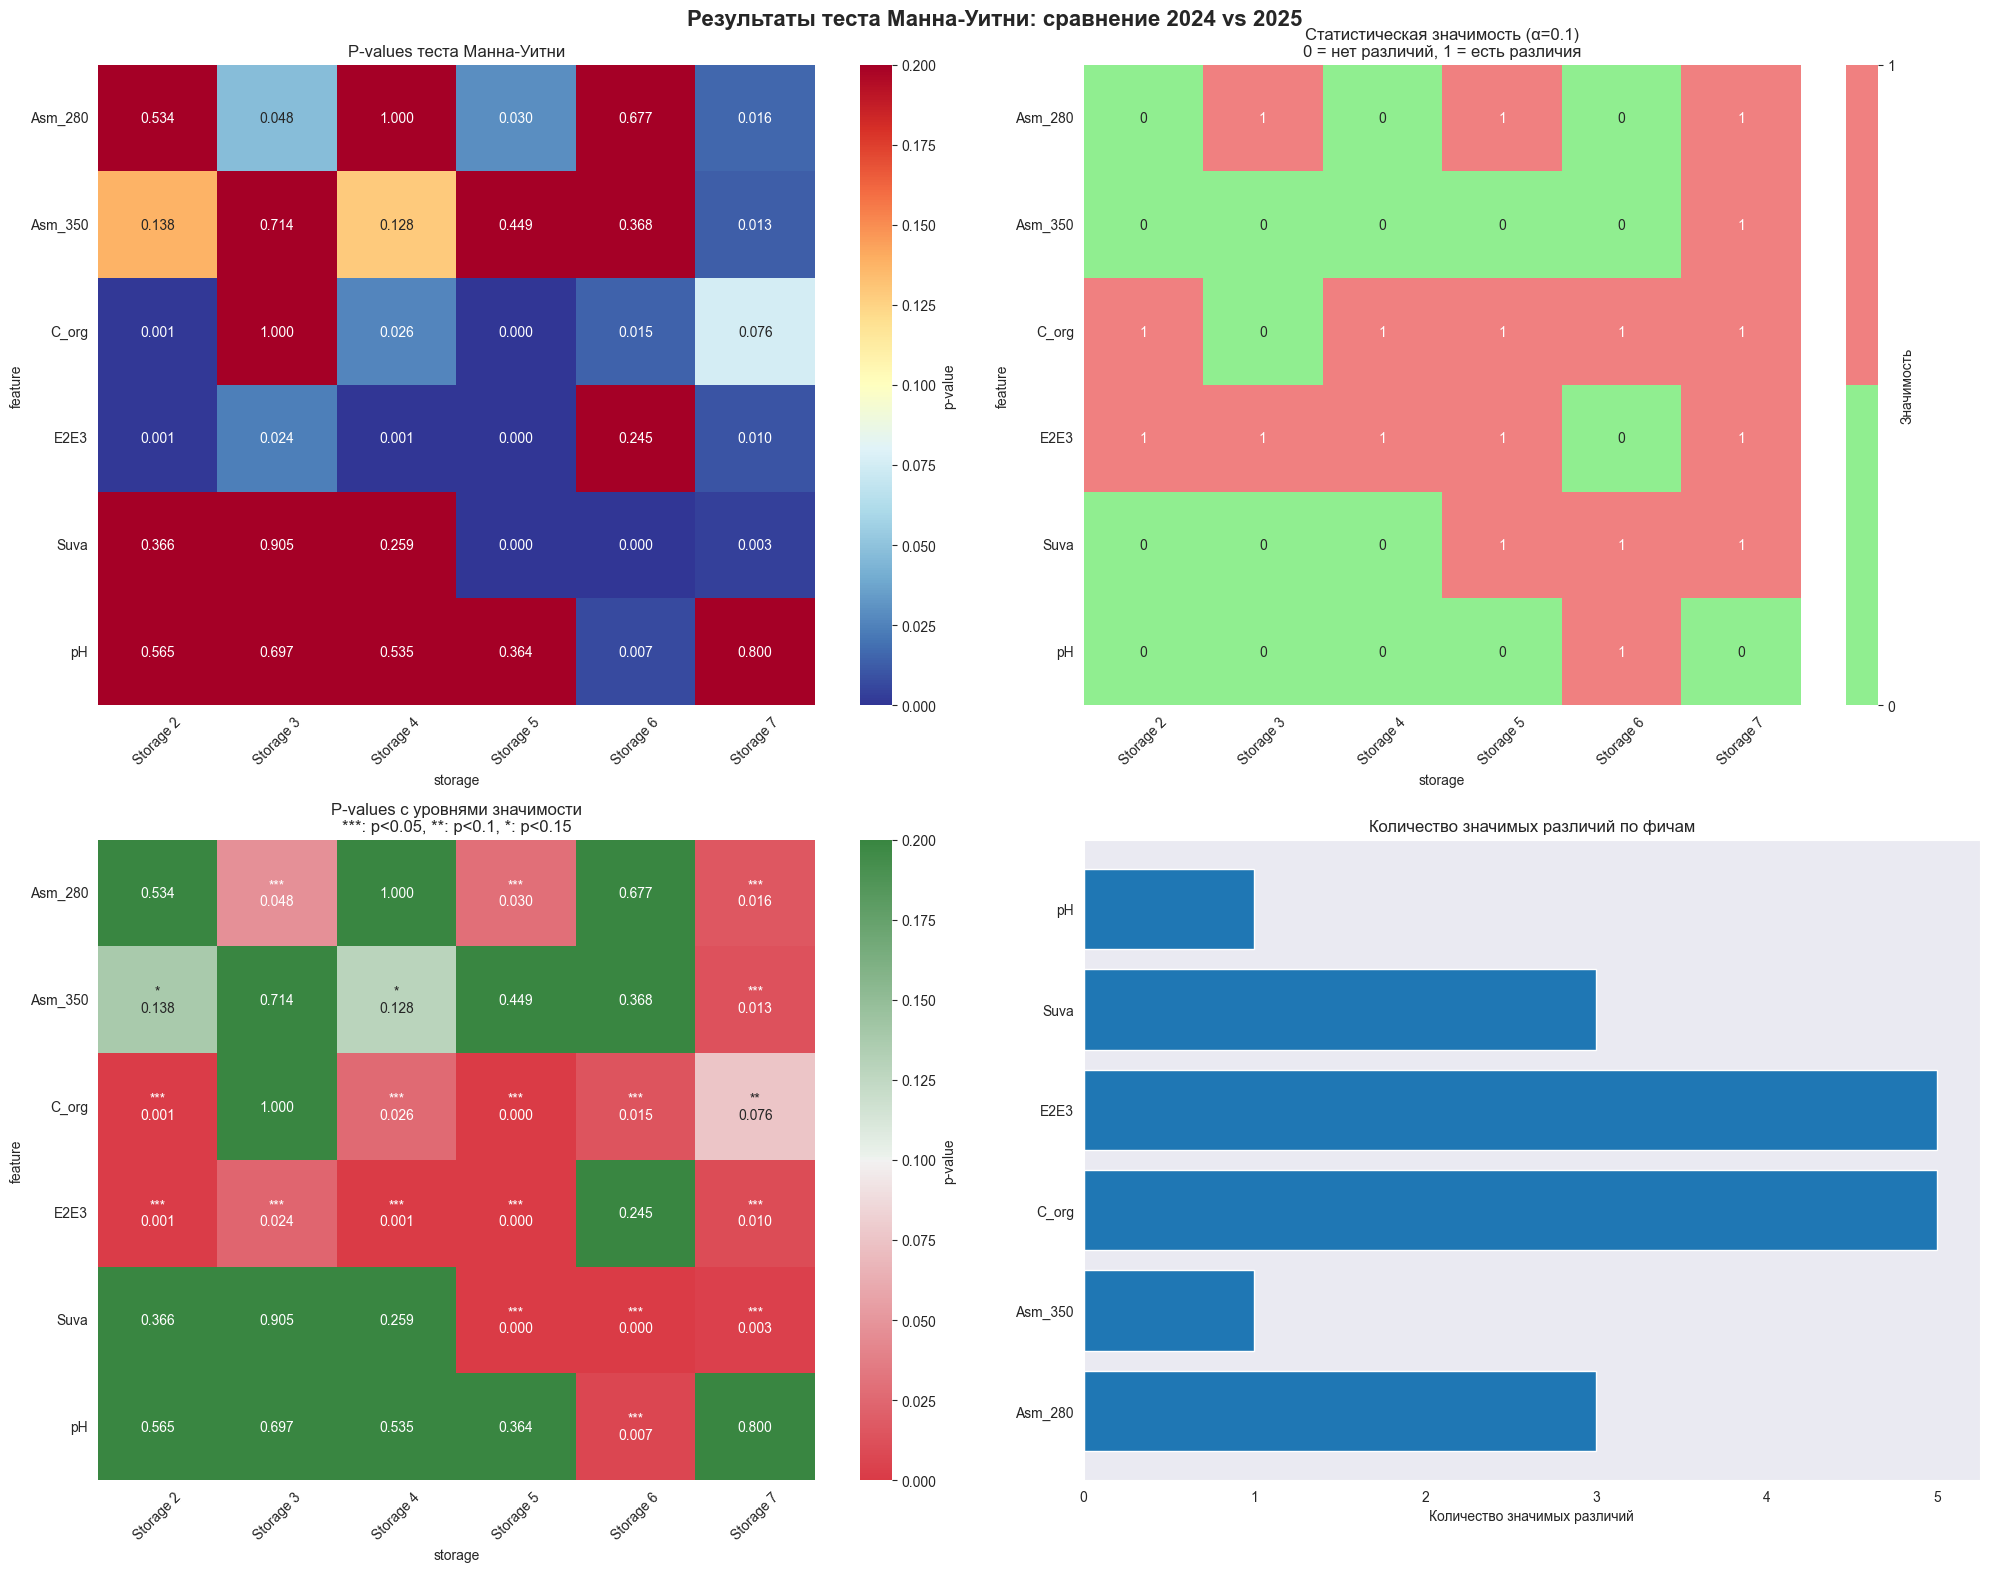

In [32]:
# Создаем DataFrame для сохранения результатов
results = []

for feature in feature_columns:
    for storage in common_storage_list:
        
        stat_data_2024 = data_list[0].sort_index().loc["ADOM", storage][feature]
        stat_data_2025 = data_list[1].sort_index().loc["ADOM", storage][feature]

        # Проверяем, что данные не пустые
        if len(stat_data_2024) > 0 and len(stat_data_2025) > 0:
            statistic, p_value = stats.mannwhitneyu(stat_data_2024, stat_data_2025)

            alpha = 0.1

            if p_value < alpha:
                significant = True

            else:
                significant = False
            
            # Сохраняем результаты
            results.append({
                'feature': feature,
                'storage': storage,
                'p_value': p_value,
                'statistic': statistic,
                'significant': significant,
                'n_2024': len(stat_data_2024),
                'n_2025': len(stat_data_2025)
            })
        else:
            print(f"Пропущено: {feature} - {storage} (нет данных)")
        

# Создаем DataFrame из результатов
results_df = pd.DataFrame(results)

# Создаем матрицу для тепловой карты
if not results_df.empty:
    # Вариант 1: Тепловая карта p-values
    pivot_pvalues = results_df.pivot(index='feature', columns='storage', values='p_value')
    
    # Вариант 2: Тепловая карта значимости (True/False)
    pivot_significant = results_df.pivot(index='feature', columns='storage', values='significant')
    
    # Вариант 3: Тепловая карта с цветами в зависимости от значимости и значения p-value
    pivot_combined = results_df.pivot(index='feature', columns='storage', values='p_value')
    
    # Создаем фигуру с несколькими графиками
    fig, axes = plt.subplots(2, 2, figsize=(20, 16))
    fig.suptitle('Результаты теста Манна-Уитни: сравнение 2024 vs 2025', fontsize=16, fontweight='bold')
    
    # График 1: Тепловая карта p-values
    sns.heatmap(pivot_pvalues, 
                annot=True, 
                fmt=".3f", 
                cmap='RdYlBu_r', 
                center=0.1,  # центр на уровне alpha
                vmin=0, 
                vmax=0.2,
                cbar_kws={'label': 'p-value'},
                ax=axes[0, 0])
    axes[0, 0].set_title('P-values теста Манна-Уитни')
    axes[0, 0].tick_params(axis='x', rotation=45)
    axes[0, 0].tick_params(axis='y', rotation=0)
    
    # График 2: Тепловая карта значимости (бинарная)
    sns.heatmap(pivot_significant.astype(int), 
                annot=True, 
                fmt="d", 
                cmap=['lightgreen', 'lightcoral'], 
                cbar_kws={'ticks': [0, 1], 'label': 'Значимость'},
                ax=axes[0, 1])
    axes[0, 1].set_title('Статистическая значимость (α=0.1)\n0 = нет различий, 1 = есть различия')
    axes[0, 1].tick_params(axis='x', rotation=45)
    axes[0, 1].tick_params(axis='y', rotation=0)
    
    # График 3: Комбинированная тепловая карта с кастомной аннотацией
    def format_annotation(p_val):
        if p_val < 0.05:
            return f"***\n{p_val:.3f}"
        elif p_val < 0.1:
            return f"**\n{p_val:.3f}"
        elif p_val < 0.15:
            return f"*\n{p_val:.3f}"
        else:
            return f"{p_val:.3f}"
    
    # Создаем матрицу для аннотаций
    annotation_matrix = pivot_combined.map(format_annotation)
    
    # Кастомная цветовая схема
    custom_cmap = sns.diverging_palette(10, 130, as_cmap=True)
    sns.heatmap(pivot_combined, 
                annot=annotation_matrix.values, 
                fmt="", 
                cmap=custom_cmap,
                center=0.1,
                vmin=0, 
                vmax=0.2,
                cbar_kws={'label': 'p-value'},
                ax=axes[1, 0])
    axes[1, 0].set_title('P-values с уровнями значимости\n***: p<0.05, **: p<0.1, *: p<0.15')
    axes[1, 0].tick_params(axis='x', rotation=45)
    axes[1, 0].tick_params(axis='y', rotation=0)
    
    # График 4: Количество значимых различий по фичам и стораджам
    summary_feature = results_df.groupby('feature')['significant'].sum()
    summary_storage = results_df.groupby('storage')['significant'].sum()
    
    axes[1, 1].barh(range(len(summary_feature)), summary_feature.values)
    axes[1, 1].set_yticks(range(len(summary_feature)))
    axes[1, 1].set_yticklabels(summary_feature.index)
    axes[1, 1].set_xlabel('Количество значимых различий')
    axes[1, 1].set_title('Количество значимых различий по фичам')
    
    plt.tight_layout()
    plt.savefig(Path.joinpath(wdir_save,"Graphs",f"mannwhitney_results.png"))
    plt.show()

    feature_summary = results_df.groupby('feature')['significant'].agg(['sum', 'count'])
    feature_summary['percent'] = (feature_summary['sum'] / feature_summary['count'] * 100).round(1)
    group_feature_summary = feature_summary.sort_values('percent', ascending=False)

    group_feature_summary.to_excel(Path.joinpath(wdir_save,'Documents','mannwhitney_groupped_results.xlsx'), index=False)
    group_feature_summary.to_html(Path.joinpath(wdir_save,'Templates','mannwhitney_groupped_results.html'), index=False)
    
else:
    print("Нет данных для построения графиков")

# Сохраняем результаты в файл
results_df.to_excel(Path.joinpath(wdir_save,'Documents','mannwhitney_results.xlsx'), index=False)
results_df.to_html(Path.joinpath(wdir_save,'Templates','mannwhitney_results.html'), index=False, encoding='utf-8-sig')

